# 02 — The 2024 training dataset: one row per parcel

Notebook 01 showed that rice has a clear Sentinel-1 signature in one 10 km square. Here we build the **training
table** for the whole study area, season **2024**:

- every parcel of the French parcel register (RPG 2024) inside the downloaded squares,
- its label (rice or not), crop, area and **spatial block** (for cross-validation, see section 4),
- its backscatter time series on a **fixed 12-day grid**,
- a few **interpretable features** taken from the physics (flood dip, summer rise).

**One satellite track only.** Two descending tracks cover the Camargue and they see the fields from different angles
(about 1 dB apart, notebook 01). Mixing them adds noise, so the download keeps only the 05:50 UTC track
(`track` in `configs/camargue.toml`): one pass every 12 days in 2024.

**ML note — training data only.** Everything here is 2024. The 2025 season is the test set and stays untouched until
the very end, so that the final score is an honest estimate for a new season.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore", module="sentinelhub")
warnings.filterwarnings("ignore", module="eolearn")
plt.rcParams["figure.dpi"] = 72  # keeps the saved notebook small

from ricesar.config import DATA_DIR, load_config
from ricesar.download import patch_name, patches_with_parcels
from ricesar.features import build_dataset, grid_dates
from ricesar.labels import load_labels, project
from ricesar.models import PHYSICS_FEATURES

config = load_config(PROJECT_ROOT / "configs" / "camargue.toml")
YEAR = 2024
labels = load_labels(config, YEAR)
bboxes = patches_with_parcels(config, labels)
crs = bboxes[0].crs.pyproj_crs()
print(f"{len(bboxes)} squares of 10 km with parcels; track {config['s1']['track']} UTC")

33 squares of 10 km with parcels; track 05:50 UTC


## 1. Downloaded area

`scripts/download_s1.py --year 2024 --area full` downloaded one EOPatch per 10 km square (the same eo-learn workflow
as in notebook 01). Squares without any declared parcel (sea, lagoon) are skipped.

missing EOPatches: none


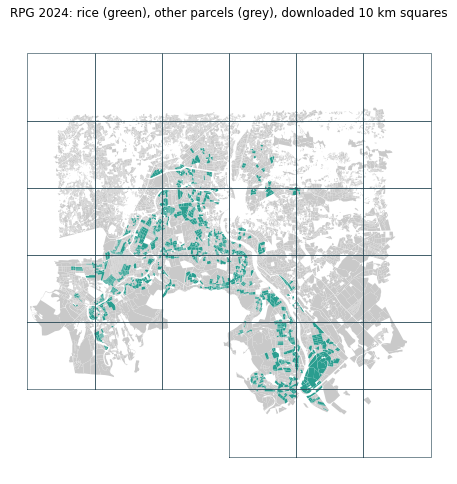

In [2]:
eopatch_root = DATA_DIR / "raw" / f"eopatches_{config['name']}_full_{YEAR}"
eopatch_dirs = [eopatch_root / patch_name(bbox) for bbox in bboxes]
missing = [path.name for path in eopatch_dirs if not path.exists()]
print("missing EOPatches:", missing or "none")

labels_utm = project(labels, crs)
fig, ax = plt.subplots(figsize=(8, 8))
labels_utm[~labels_utm["is_rice"]].plot(ax=ax, color="#c9c9c9", linewidth=0)
labels_utm[labels_utm["is_rice"]].plot(ax=ax, color="#2a9d8f", linewidth=0)
for bbox in bboxes:
    x, y = bbox.geometry.exterior.xy
    ax.plot(x, y, color="#264653", linewidth=0.6)
ax.set_title(f"RPG {YEAR}: rice (green), other parcels (grey), downloaded 10 km squares")
ax.set_axis_off()
plt.show()

## 2. Build the table

`build_dataset` (in `src/ricesar/features.py`):
1. averages the valid pixels of each parcel on each pass (in linear units; parcels split across squares are combined),
2. keeps parcels observed on at least 75 % of the passes (≥ 5 valid pixels after the 20 m edge buffer),
3. puts each parcel's series on a fixed **12-day grid** from 1 March (`VH_db_00`, `VH_db_01`, ...). In 2024 each bin
   holds one pass; in 2025 (two satellites) about two, which are averaged, so both years give the same columns,
4. computes the physics features in the season windows of the config:

| feature | meaning |
|---|---|
| `vh_flood_min` | lowest VH in the flooding window (Apr 15 – Jun 15): how dark did it get? |
| `vh_peak_max` | highest VH in the growth window (Jul 15 – Sep 30) |
| `vh_rise` | `vh_peak_max − vh_flood_min`: the dip-then-rise of rice |
| `vv_flood_min` | lowest VV in the flooding window |
| `ratio_flood_min` | lowest VH/VV ratio in the flooding window (on water VH drops more than VV) |
| `ratio_peak_mean` | mean VH/VV ratio in the growth window |

The table is cached in `data/processed/`; delete the file to rebuild it.

In [3]:
dataset_path = DATA_DIR / "processed" / f"dataset_{config['name']}_{YEAR}.csv"
excluded_path = DATA_DIR / "processed" / f"excluded_{config['name']}_{YEAR}.csv"
if dataset_path.exists():
    data = pd.read_csv(dataset_path, index_col="pid")
    excluded = pd.read_csv(excluded_path)
else:
    data, excluded_gdf = build_dataset(config, YEAR, eopatch_dirs, labels, bboxes)
    excluded = pd.DataFrame(excluded_gdf.drop(columns="geometry"))
    dataset_path.parent.mkdir(parents=True, exist_ok=True)
    data.to_csv(dataset_path)
    excluded.to_csv(excluded_path, index=False)

print(f"{len(data)} parcels in the table, {data.shape[1]} columns")
data[["is_rice", "code_cultu", "group_name", "surf_parc", "block"] + PHYSICS_FEATURES].head()

13613 parcels in the table, 80 columns


,is_rice,code_cultu,group_name,surf_parc,block,vh_flood_min,vh_peak_max,vh_rise,vv_flood_min,ratio_flood_min,ratio_peak_mean
pid,,,,,,,,,,,
7062,False,EPI,vegetables/flowers,0.59,127_970,-26.674096,-11.096652,15.577444,-15.258007,-11.875111,-5.110524
7074,False,OLI,olives,0.59,127_968,-17.835857,-15.335849,2.500008,-11.615895,-7.409278,-6.890125
7202,False,LUZ,fodder,0.61,121_967,-17.613863,-16.748086,0.865777,-10.869709,-7.275589,-8.115017
7205,False,LUZ,fodder,0.61,123_968,-19.511676,-16.899324,2.612352,-12.928717,-6.582959,-8.388748
7341,False,OLI,olives,0.63,127_968,-16.564518,-14.476226,2.088292,-11.441621,-5.122896,-5.576624


## 3. Which parcels are left out?

Parcels that are too small or too narrow keep (almost) no pixels after shrinking by 20 m. We can't measure them
reliably with 20 m radar pixels, so they are not in the table. That is a **limitation to state** in the results:
the model is evaluated on parcels large enough to measure, not on all parcels.

In [4]:
summary = pd.DataFrame({
    "parcels": [len(data), len(excluded)],
    "rice parcels": [int(data["is_rice"].sum()), int(excluded["is_rice"].sum())],
    "median area (ha)": [data["surf_parc"].median(), excluded["surf_parc"].median()],
    "total area (ha)": [data["surf_parc"].sum().round(), excluded["surf_parc"].sum().round()],
}, index=["in the table", "left out"])
rice_area_share = excluded.loc[excluded["is_rice"], "surf_parc"].sum() / (
    excluded.loc[excluded["is_rice"], "surf_parc"].sum() + data.loc[data["is_rice"], "surf_parc"].sum()
)
print(f"Rice area left out: {rice_area_share:.1%}")
summary

Rice area left out: 0.2%


,parcels,rice parcels,median area (ha),total area (ha)
in the table,13613,1524,3.15,108378.0
left out,9375,42,0.26,3857.0


## 4. Class balance and why accuracy misleads

Only a small share of the parcels are rice. A "model" that always answers *not rice* would already be right for
most parcels, so its **accuracy** would look great while it finds no rice at all. That's why we'll judge models by
**precision** (of the parcels called rice, how many are rice), **recall** (of the rice parcels, how many were found),
their combination **F1**, and **PR-AUC** (how well the model *ranks* rice above non-rice, over all thresholds).

In [5]:
share = data["is_rice"].mean()
print(f"rice: {data['is_rice'].sum()} of {len(data)} parcels ({share:.1%}); 'never rice' would be {1 - share:.1%} accurate")
data.groupby("group_name").size().sort_values(ascending=False).head(10)

rice: 1524 of 13613 parcels (11.2%); 'never rice' would be 88.8% accurate


group_name
vineyards              2017
permanent grassland    1707
other cereals          1603
orchards               1588
rice                   1524
fodder                 1012
summer pasture          902
vegetables/flowers      795
temporary grassland     578
olives                  429
dtype: int64

## 5. Spatial blocks for honest cross-validation

Cross-validation repeatedly trains on part of the data and tests on the rest. If the test parcels are the
**neighbours** of training parcels (same farm, same irrigation canal, same soil, often the same sowing day), they
are almost copies, and the score says little about new places. This is **spatial autocorrelation**, and it makes a
random split too optimistic (a form of data leakage).

So each parcel gets a **5 km block** (from its centroid), and whole blocks go to either training or testing. 5 km is
larger than a typical farm in the delta, so most farms fall in one block. In notebook 03 we compare this with a random split.

98 blocks; parcels per block: median 107, max 468; blocks with rice: 46


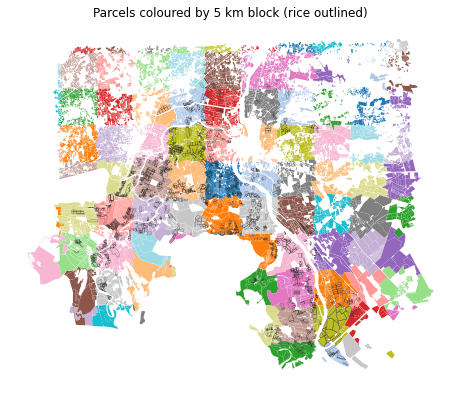

In [6]:
block_sizes = data.groupby("block").agg(parcels=("is_rice", "size"), rice=("is_rice", "sum"))
print(f"{len(block_sizes)} blocks; parcels per block: median {block_sizes['parcels'].median():.0f}, "
      f"max {block_sizes['parcels'].max()}; blocks with rice: {(block_sizes['rice'] > 0).sum()}")

in_table = labels_utm.set_index("pid").loc[data.index]
codes = pd.Series(pd.factorize(data["block"])[0], index=data.index)
fig, ax = plt.subplots(figsize=(8, 8))
in_table.assign(code=codes % 20).plot(ax=ax, column="code", cmap="tab20", linewidth=0)
in_table[data["is_rice"]].boundary.plot(ax=ax, color="black", linewidth=0.2)
ax.set_title("Parcels coloured by 5 km block (rice outlined)")
ax.set_axis_off()
plt.show()

## 6. The rice curve on the 12-day grid, whole area

The same picture as in notebook 01, now for all squares and on the fixed grid that the models will use.

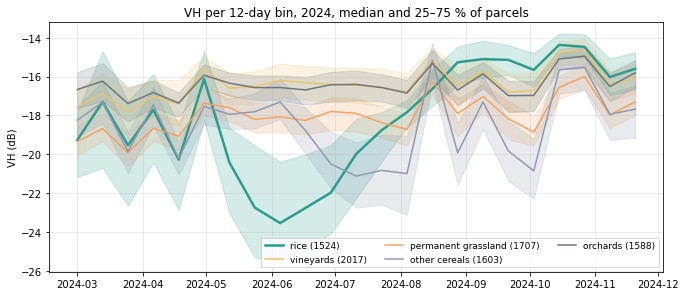

In [7]:
dates = grid_dates(config, YEAR)
vh_cols = [f"VH_db_{b:02d}" for b in range(len(dates))]
groups = ["rice"] + data.loc[~data["is_rice"], "group_name"].value_counts().head(4).index.tolist()
colors = dict(zip(groups, ["#2a9d8f", "#e9c46a", "#f4a261", "#8d99ae", "#6c757d"]))

fig, ax = plt.subplots(figsize=(11, 4.5))
for group in groups:
    values = data.loc[data["group_name"] == group, vh_cols]
    ax.plot(dates, values.median(), color=colors[group], linewidth=2.5 if group == "rice" else 1.5,
            label=f"{group} ({len(values)})")
    ax.fill_between(dates, values.quantile(0.25), values.quantile(0.75), color=colors[group], alpha=0.2)
ax.set_ylabel("VH (dB)")
ax.set_title(f"VH per 12-day bin, {YEAR}, median and 25–75 % of parcels")
ax.legend(ncol=3, fontsize=9)
ax.grid(alpha=0.3)
plt.show()

## 7. The physics features: rice vs other

Each dot is a parcel. Rice should sit in the corner "dark during flooding" (left) and "strong rise" (top).
Parcels of other crops in that corner are the ones a model will confuse with rice.

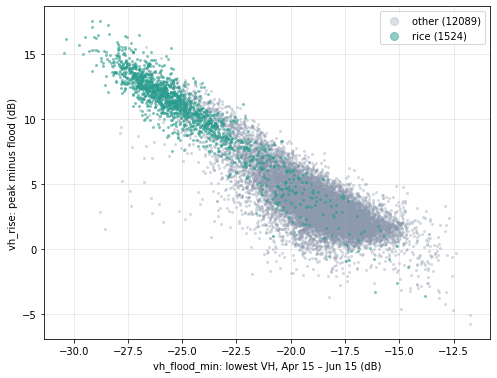

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
other, rice = data[~data["is_rice"]], data[data["is_rice"]]
ax.scatter(other["vh_flood_min"], other["vh_rise"], s=4, alpha=0.3, color="#8d99ae", label=f"other ({len(other)})")
ax.scatter(rice["vh_flood_min"], rice["vh_rise"], s=4, alpha=0.5, color="#2a9d8f", label=f"rice ({len(rice)})")
ax.set_xlabel("vh_flood_min: lowest VH, Apr 15 – Jun 15 (dB)")
ax.set_ylabel("vh_rise: peak minus flood (dB)")
ax.legend(markerscale=4)
ax.grid(alpha=0.3)
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "02_features_scatter.png", dpi=90, bbox_inches="tight")
plt.show()

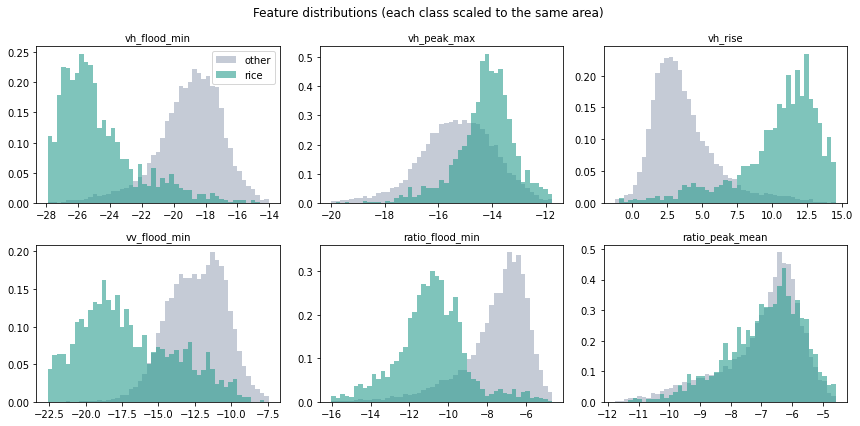

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, feature in zip(axes.flat, PHYSICS_FEATURES):
    bins = np.linspace(data[feature].quantile(0.005), data[feature].quantile(0.995), 50)
    ax.hist(other[feature], bins=bins, density=True, alpha=0.5, color="#8d99ae", label="other")
    ax.hist(rice[feature], bins=bins, density=True, alpha=0.6, color="#2a9d8f", label="rice")
    ax.set_title(feature, fontsize=10)
axes[0, 0].legend()
fig.suptitle("Feature distributions (each class scaled to the same area)")
plt.tight_layout()
plt.show()

## Summary

- The table has one row per parcel with label, crop, area, spatial block, the 12-day time grid (VV, VH, VH/VV)
  and six physics features. Saved to `data/processed/dataset_camargue_2024.csv`.
- Small parcels without enough clean pixels are left out (section 3); the results apply to measurable parcels.
- Rice is a minority class, so we use precision, recall, F1 and PR-AUC instead of accuracy.
- Whole 5 km blocks are kept together in cross-validation to avoid leakage between neighbouring parcels.

**Next (notebook 03):** compare a hand-made rule, logistic regression and LightGBM with spatially blocked
cross-validation, and see how much a random split would overstate the scores.